# Machine Learning-Based Non-Performing Loan Risk Prediction for Sri Lankan Banking Data

## Problem Definition

The objective of this project is to develop a machine learning model that can predict whether a bank loan is likely to become Performing or Non-Performing.

This is a binary classification problem.

The project uses a Sri Lankan banking loan dataset and compares multiple machine learning models to identify the most suitable model for Non-Performing Loan (NPL) risk prediction.

In [79]:
# Import libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    ConfusionMatrixDisplay
)

import joblib

In [80]:

# Load dataset and keep "None" as a valid text category

df = pd.read_excel(
    "BankDataset NPL.xlsx",
    sheet_name="Sheet1",
    keep_default_na=False
)

print("Dataset shape:", df.shape)

df.head()

Dataset shape: (1806, 11)


,ProductID,Loan ID,Product,LoanBalance,Age,Income,Status,CustomerCategory,Gender,Education,CRIB Category
0,1,CUST-00299,Housing Loan,3675464,24,234690,Performing,Business Medium,Male,Degree,D
1,2,CUST-00986,Leasing,1691773,57,52097,Performing,Business Medium,Male,Degree,D
2,3,CUST-00916,Business Loan,4078848,31,452725,Performing,Business Medium,Male,A/L,A
3,4,CUST-00719,Leasing,3852608,47,183226,Performing,Retail,Male,Degree,C
4,4,CUST-01169,Business Loan,92165,28,226824,Performing,Business Small,Male,O/L,B


In [81]:
# Display basic dataset information

df.info()

# Display statistical summary of numerical columns

df.describe()

# Check missing values

df.isnull().sum()

# Check duplicate rows

print("Duplicate rows:", df.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1806 entries, 0 to 1805
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   ProductID         1806 non-null   int64 
 1   Loan ID           1806 non-null   object
 2   Product           1806 non-null   object
 3   LoanBalance       1806 non-null   int64 
 4   Age               1806 non-null   int64 
 5   Income            1806 non-null   int64 
 6   Status            1806 non-null   object
 7   CustomerCategory  1806 non-null   object
 8   Gender            1806 non-null   object
 9   Education         1806 non-null   object
 10  CRIB Category     1806 non-null   object
dtypes: int64(4), object(7)
memory usage: 155.3+ KB
Duplicate rows: 0


In [82]:
# Check target class distribution

print(df["Status"].value_counts())

print(
    df["Status"].value_counts(normalize=True) * 100
)

Status
Performing        1605
Non Performing     201
Name: count, dtype: int64
Status
Performing        88.870432
Non Performing    11.129568
Name: proportion, dtype: float64


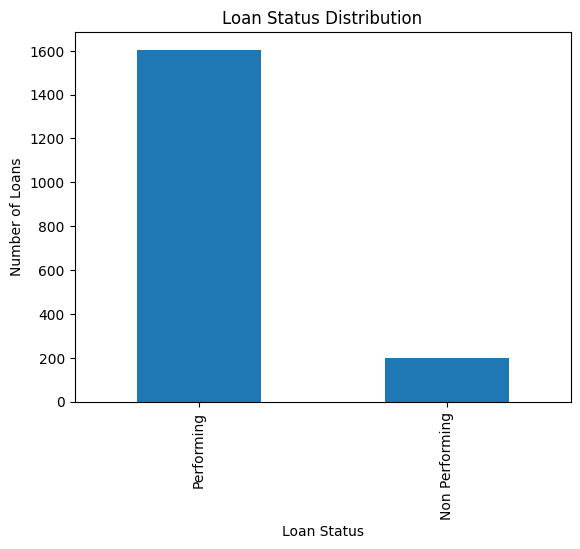

In [83]:
# Visualize target class distribution

df["Status"].value_counts().plot(
    kind="bar"
)

plt.title("Loan Status Distribution")
plt.xlabel("Loan Status")
plt.ylabel("Number of Loans")
plt.show()

In [84]:
# Display unique values in categorical columns

categorical_columns = [
    "Product",
    "CustomerCategory",
    "Gender",
    "Education",
    "CRIB Category"
]

for column in categorical_columns:

    print("\n", column)

    print(
        df[column].value_counts()
    )


 Product
Product
Business Loan    610
Leasing          356
Housing Loan     350
Gold Loan        322
Personal Loan    168
Name: count, dtype: int64

 CustomerCategory
CustomerCategory
Retail             760
Business Small     615
Business Medium    427
PRV                  4
Name: count, dtype: int64

 Gender
Gender
Male      1004
Female     802
Name: count, dtype: int64

 Education
Education
Degree     473
O/L        467
A/L        456
None       408
Masters      1
Diploma      1
Name: count, dtype: int64

 CRIB Category
CRIB Category
E    506
A    348
D    337
B    316
C    299
Name: count, dtype: int64


In [85]:
# Compare loan status by CRIB category

crib_status = pd.crosstab(
    df["CRIB Category"],
    df["Status"]
)

crib_status

# Calculate NPL percentage for each CRIB category

crib_npl_rate = pd.crosstab(
    df["CRIB Category"],
    df["Status"],
    normalize="index"
) * 100

crib_npl_rate

Status,Non Performing,Performing
CRIB Category,,
A,0.000000,100.000000
B,0.000000,100.000000
C,1.337793,98.662207
D,9.198813,90.801187
E,32.806324,67.193676


In [86]:
# Remove identifier columns

df_model = df.drop(
    columns=[
        "ProductID",
        "Loan ID"
    ]
)

df_model.head()

,Product,LoanBalance,Age,Income,Status,CustomerCategory,Gender,Education,CRIB Category
0,Housing Loan,3675464,24,234690,Performing,Business Medium,Male,Degree,D
1,Leasing,1691773,57,52097,Performing,Business Medium,Male,Degree,D
2,Business Loan,4078848,31,452725,Performing,Business Medium,Male,A/L,A
3,Leasing,3852608,47,183226,Performing,Retail,Male,Degree,C
4,Business Loan,92165,28,226824,Performing,Business Small,Male,O/L,B


In [87]:
# Convert target variable to binary values

df_model["Status"] = df_model["Status"].map({
    "Performing": 0,
    "Non Performing": 1
})

df_model["Status"].value_counts()

,count
Status,
0,1605
1,201


In [88]:
# Separate input features and target

X = df_model.drop(
    columns=["Status"]
)

y = df_model["Status"]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

Feature shape: (1806, 8)
Target shape: (1806,)


In [89]:
# Define numerical and categorical features

numerical_features = [
    "LoanBalance",
    "Age",
    "Income"
]

categorical_features = [
    "Product",
    "CustomerCategory",
    "Gender",
    "Education",
    "CRIB Category"
]

print("Numerical features:")
print(numerical_features)

print("\nCategorical features:")
print(categorical_features)

Numerical features:
['LoanBalance', 'Age', 'Income']

Categorical features:
['Product', 'CustomerCategory', 'Gender', 'Education', 'CRIB Category']


In [90]:
# Split data into training, validation and test sets

X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Testing samples:", len(X_test))

Training samples: 1264
Validation samples: 271
Testing samples: 271


In [91]:
# Check class distribution after splitting

print("Training distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nValidation distribution:")
print(y_val.value_counts(normalize=True) * 100)

print("\nTest distribution:")
print(y_test.value_counts(normalize=True) * 100)

Training distribution:
Status
0    88.844937
1    11.155063
Name: proportion, dtype: float64

Validation distribution:
Status
0    88.929889
1    11.070111
Name: proportion, dtype: float64

Test distribution:
Status
0    88.929889
1    11.070111
Name: proportion, dtype: float64


## 6. Feature Preprocessing

The numerical features are standardized using StandardScaler.

Categorical features are transformed using One-Hot Encoding so that machine learning algorithms can process them.

The Education value `None` is treated as a valid category and not as a missing value.

In [92]:
# Numerical preprocessing

numerical_transformer = Pipeline(
    steps=[
        (
            "scaler",
            StandardScaler()
        )
    ]
)


# Categorical preprocessing

categorical_transformer = Pipeline(
    steps=[
        (
            "encoder",
            OneHotEncoder(
                handle_unknown="ignore"
            )
        )
    ]
)


# Combine preprocessing steps

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            numerical_transformer,
            numerical_features
        ),
        (
            "cat",
            categorical_transformer,
            categorical_features
        )
    ]
)

In [93]:
# Create Logistic Regression pipeline

logistic_model = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "model",
            LogisticRegression(
                class_weight="balanced",
                max_iter=1000,
                random_state=42
            )
        )
    ]
)

# Train Logistic Regression model

logistic_model.fit(
    X_train,
    y_train
)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('scaler',
                                                                   StandardScaler())]),
                                                  ['LoanBalance', 'Age',
                                                   'Income']),
                                                 ('cat',
                                                  Pipeline(steps=[('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['Product',
                                                   'CustomerCategory', 'Gender',
                                                   'Education',
                                                   'CRIB Category'])])),
                ('model',
                 LogisticRegression(class_weight='balanced', max_iter=1000,
                                    random_state=42))])

In [94]:
# Predict validation data

logistic_predictions = logistic_model.predict(
    X_val
)

logistic_probabilities = logistic_model.predict_proba(
    X_val
)[:, 1]

In [95]:
# Evaluate Logistic Regression

logistic_accuracy = accuracy_score(
    y_val,
    logistic_predictions
)

logistic_precision = precision_score(
    y_val,
    logistic_predictions
)

logistic_recall = recall_score(
    y_val,
    logistic_predictions
)

logistic_f1 = f1_score(
    y_val,
    logistic_predictions
)

logistic_auc = roc_auc_score(
    y_val,
    logistic_probabilities
)


print("Accuracy:", round(logistic_accuracy, 4))
print("Precision:", round(logistic_precision, 4))
print("Recall:", round(logistic_recall, 4))
print("F1 Score:", round(logistic_f1, 4))
print("ROC-AUC:", round(logistic_auc, 4))

Accuracy: 0.6974
Precision: 0.2547
Recall: 0.9
F1 Score: 0.3971
ROC-AUC: 0.8726


In [96]:
# Display detailed classification results

print(
    classification_report(
        y_val,
        logistic_predictions
    )
)

              precision    recall  f1-score   support

           0       0.98      0.67      0.80       241
           1       0.25      0.90      0.40        30

    accuracy                           0.70       271
   macro avg       0.62      0.79      0.60       271
weighted avg       0.90      0.70      0.75       271



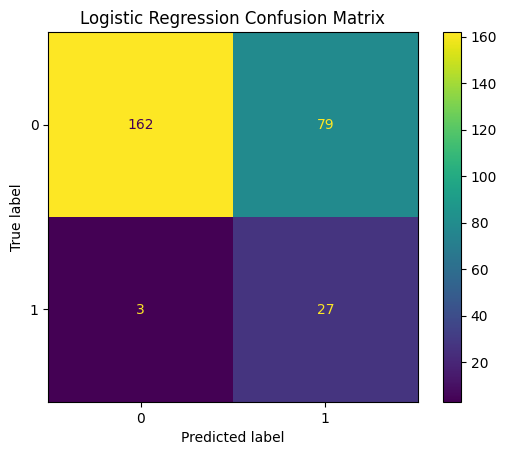

In [97]:
# Display confusion matrix

ConfusionMatrixDisplay.from_predictions(
    y_val,
    logistic_predictions
)

plt.title(
    "Logistic Regression Confusion Matrix"
)

plt.show()

## 8. Random Forest Model

Random Forest is an ensemble learning model that combines multiple decision trees.

It can capture non-linear relationships and interactions between loan characteristics.

Because the target classes are imbalanced, balanced class weights are used to give more importance to the Non-Performing Loan class.

In [98]:
# Create Random Forest pipeline

rf_model = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "model",
            RandomForestClassifier(
                n_estimators=200,
                max_depth=10,
                min_samples_split=5,
                min_samples_leaf=2,
                class_weight="balanced",
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

# Train Random Forest model

rf_model.fit(
    X_train,
    y_train
)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('scaler',
                                                                   StandardScaler())]),
                                                  ['LoanBalance', 'Age',
                                                   'Income']),
                                                 ('cat',
                                                  Pipeline(steps=[('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['Product',
                                                   'CustomerCategory', 'Gender',
                                                   'Education',
                                                   'CRIB Category'])])),
                ('model',
                 RandomForestClassifier(class_weight='balanced', max_depth=10,
                                        min_samples_leaf=2, min_samples_split=5,
                                        n_estimators=200, n_jobs=-1,
                                        random_state=42))])

In [99]:
# Predict validation data

rf_predictions = rf_model.predict(
    X_val
)

rf_probabilities = rf_model.predict_proba(
    X_val
)[:, 1]

Accuracy: 0.8192
Precision: 0.3137
Recall: 0.5333
F1 Score: 0.3951
ROC-AUC: 0.8632
              precision    recall  f1-score   support

           0       0.94      0.85      0.89       241
           1       0.31      0.53      0.40        30

    accuracy                           0.82       271
   macro avg       0.63      0.69      0.64       271
weighted avg       0.87      0.82      0.84       271



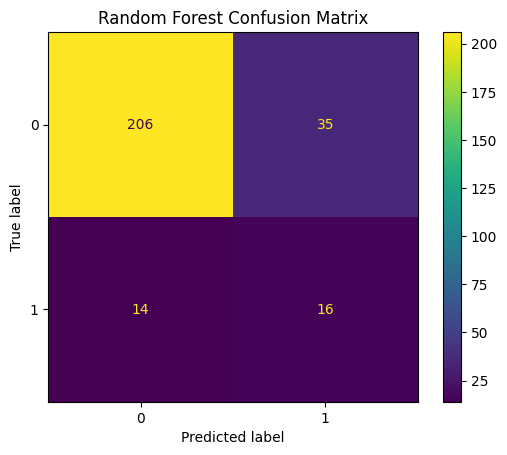

In [100]:
# Evaluate Random Forest

rf_accuracy = accuracy_score(
    y_val,
    rf_predictions
)

rf_precision = precision_score(
    y_val,
    rf_predictions
)

rf_recall = recall_score(
    y_val,
    rf_predictions
)

rf_f1 = f1_score(
    y_val,
    rf_predictions
)

rf_auc = roc_auc_score(
    y_val,
    rf_probabilities
)


print("Accuracy:", round(rf_accuracy, 4))
print("Precision:", round(rf_precision, 4))
print("Recall:", round(rf_recall, 4))
print("F1 Score:", round(rf_f1, 4))
print("ROC-AUC:", round(rf_auc, 4))

print(
    classification_report(
        y_val,
        rf_predictions
    )
)

ConfusionMatrixDisplay.from_predictions(
    y_val,
    rf_predictions
)

plt.title(
    "Random Forest Confusion Matrix"
)

plt.show()

## 9. XGBoost Model

XGBoost is a gradient boosting algorithm that builds decision trees sequentially.

Each new tree attempts to correct errors made by the previous trees.

Because the dataset is imbalanced, the positive class weight is adjusted so that Non-Performing Loans receive greater importance during training.

In [101]:
# Calculate class imbalance ratio

negative_count = (
    y_train == 0
).sum()

positive_count = (
    y_train == 1
).sum()

scale_pos_weight = (
    negative_count / positive_count
)

print(
    "Scale Pos Weight:",
    round(scale_pos_weight, 2)
)

Scale Pos Weight: 7.96


In [102]:
# Create XGBoost pipeline

xgb_model = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "model",
            XGBClassifier(
                n_estimators=200,
                max_depth=5,
                learning_rate=0.05,
                subsample=0.8,
                colsample_bytree=0.8,
                scale_pos_weight=scale_pos_weight,
                eval_metric="logloss",
                random_state=42
            )
        )
    ]
)

# Train XGBoost model

xgb_model.fit(
    X_train,
    y_train
)

# Predict validation data

xgb_predictions = xgb_model.predict(
    X_val
)

xgb_probabilities = xgb_model.predict_proba(
    X_val
)[:, 1]



In [103]:
# Evaluate XGBoost

xgb_accuracy = accuracy_score(
    y_val,
    xgb_predictions
)

xgb_precision = precision_score(
    y_val,
    xgb_predictions
)

xgb_recall = recall_score(
    y_val,
    xgb_predictions
)

xgb_f1 = f1_score(
    y_val,
    xgb_predictions
)

xgb_auc = roc_auc_score(
    y_val,
    xgb_probabilities
)


print("Accuracy:", round(xgb_accuracy, 4))
print("Precision:", round(xgb_precision, 4))
print("Recall:", round(xgb_recall, 4))
print("F1 Score:", round(xgb_f1, 4))
print("ROC-AUC:", round(xgb_auc, 4))



Accuracy: 0.8413
Precision: 0.3673
Recall: 0.6
F1 Score: 0.4557
ROC-AUC: 0.861


              precision    recall  f1-score   support

           0       0.95      0.87      0.91       241
           1       0.37      0.60      0.46        30

    accuracy                           0.84       271
   macro avg       0.66      0.74      0.68       271
weighted avg       0.88      0.84      0.86       271



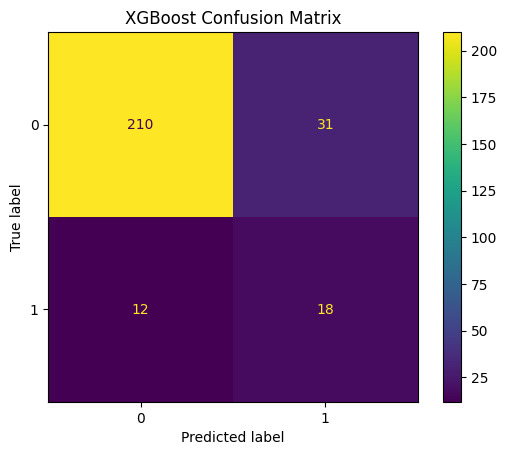

In [104]:
print(
    classification_report(
        y_val,
        xgb_predictions
    )
)

ConfusionMatrixDisplay.from_predictions(
    y_val,
    xgb_predictions
)

plt.title(
    "XGBoost Confusion Matrix"
)

plt.show()

In [105]:
model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "XGBoost"
    ],
    "Accuracy": [
        logistic_accuracy,
        rf_accuracy,
        xgb_accuracy
    ],
    "Precision": [
        logistic_precision,
        rf_precision,
        xgb_precision
    ],
    "Recall": [
        logistic_recall,
        rf_recall,
        xgb_recall
    ],
    "F1 Score": [
        logistic_f1,
        rf_f1,
        xgb_f1
    ],
    "ROC-AUC": [
        logistic_auc,
        rf_auc,
        xgb_auc
    ]
})

model_comparison

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.697417,0.254717,0.900000,0.397059,0.872614
1,Random Forest,0.819188,0.313725,0.533333,0.395062,0.863209
2,XGBoost,0.841328,0.367347,0.600000,0.455696,0.860996


## 10. Initial Model Comparison

The three models show different strengths.

- Logistic Regression achieved the highest Recall, detecting most Non-Performing Loans, but it produced many false positives.
- Random Forest achieved higher Accuracy than Logistic Regression but lower Recall.
- XGBoost achieved the highest F1-score, providing the best balance between Precision and Recall at this stage.

Because detecting risky loans is important, model selection should consider Recall and F1-score rather than Accuracy alone.

## 11. Model Tuning

A small number of important hyperparameter combinations are tested using the validation set.

The test set is kept untouched until the final evaluation.

In [106]:
# Test a small number of Random Forest settings

rf_tuning_results = []

for n_estimators in [100, 200, 300]:
    for max_depth in [6, 10, 14]:

        model = Pipeline(
            steps=[
                (
                    "preprocessor",
                    preprocessor
                ),
                (
                    "model",
                    RandomForestClassifier(
                        n_estimators=n_estimators,
                        max_depth=max_depth,
                        min_samples_split=5,
                        min_samples_leaf=2,
                        class_weight="balanced",
                        random_state=42,
                        n_jobs=-1
                    )
                )
            ]
        )

        model.fit(X_train, y_train)

        predictions = model.predict(X_val)

        rf_tuning_results.append({
            "n_estimators": n_estimators,
            "max_depth": max_depth,
            "Precision": precision_score(
                y_val,
                predictions
            ),
            "Recall": recall_score(
                y_val,
                predictions
            ),
            "F1 Score": f1_score(
                y_val,
                predictions
            )
        })


rf_tuning_df = pd.DataFrame(
    rf_tuning_results
)

rf_tuning_df.sort_values(
    "F1 Score",
    ascending=False
)

best_rf_params = rf_tuning_df.sort_values(
    "F1 Score",
    ascending=False
).iloc[0]

best_rf_params

,0
n_estimators,100.000000
max_depth,6.000000
Precision,0.295455
Recall,0.866667
F1 Score,0.440678


In [107]:
# Test a small number of XGBoost settings

xgb_tuning_results = []

for n_estimators in [100, 200, 300]:
    for max_depth in [3, 5, 7]:
        for learning_rate in [0.05, 0.1]:

            model = Pipeline(
                steps=[
                    (
                        "preprocessor",
                        preprocessor
                    ),
                    (
                        "model",
                        XGBClassifier(
                            n_estimators=n_estimators,
                            max_depth=max_depth,
                            learning_rate=learning_rate,
                            subsample=0.8,
                            colsample_bytree=0.8,
                            scale_pos_weight=scale_pos_weight,
                            eval_metric="logloss",
                            random_state=42
                        )
                    )
                ]
            )

            model.fit(
                X_train,
                y_train
            )

            predictions = model.predict(
                X_val
            )

            xgb_tuning_results.append({
                "n_estimators": n_estimators,
                "max_depth": max_depth,
                "learning_rate": learning_rate,
                "Precision": precision_score(
                    y_val,
                    predictions
                ),
                "Recall": recall_score(
                    y_val,
                    predictions
                ),
                "F1 Score": f1_score(
                    y_val,
                    predictions
                )
            })


xgb_tuning_df = pd.DataFrame(
    xgb_tuning_results
)

xgb_tuning_df.sort_values(
    "F1 Score",
    ascending=False
)

best_xgb_params = xgb_tuning_df.sort_values(
    "F1 Score",
    ascending=False
).iloc[0]

best_xgb_params

,15
n_estimators,300.000000
max_depth,5.000000
learning_rate,0.100000
Precision,0.517241
Recall,0.500000
F1 Score,0.508475


In [108]:
# Combine training and validation data

X_train_final = pd.concat(
    [X_train, X_val]
)

y_train_final = pd.concat(
    [y_train, y_val]
)

print(
    "Final training samples:",
    len(X_train_final)
)

print(
    "Final test samples:",
    len(X_test)
)

Final training samples: 1535
Final test samples: 271


In [109]:
# Train final Random Forest

final_rf = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "model",
            RandomForestClassifier(
                n_estimators=int(
                    best_rf_params[
                        "n_estimators"
                    ]
                ),
                max_depth=int(
                    best_rf_params[
                        "max_depth"
                    ]
                ),
                min_samples_split=5,
                min_samples_leaf=2,
                class_weight="balanced",
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

final_rf.fit(
    X_train_final,
    y_train_final
)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('scaler',
                                                                   StandardScaler())]),
                                                  ['LoanBalance', 'Age',
                                                   'Income']),
                                                 ('cat',
                                                  Pipeline(steps=[('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['Product',
                                                   'CustomerCategory', 'Gender',
                                                   'Education',
                                                   'CRIB Category'])])),
                ('model',
                 RandomForestClassifier(class_weight='balanced', max_depth=6,
                                        min_samples_leaf=2, min_samples_split=5,
                                        n_jobs=-1, random_state=42))])

In [110]:
# Recalculate class weight using final training data

negative_count_final = (
    y_train_final == 0
).sum()

positive_count_final = (
    y_train_final == 1
).sum()

scale_pos_weight_final = (
    negative_count_final /
    positive_count_final
)


# Train final XGBoost

final_xgb = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "model",
            XGBClassifier(
                n_estimators=int(
                    best_xgb_params[
                        "n_estimators"
                    ]
                ),
                max_depth=int(
                    best_xgb_params[
                        "max_depth"
                    ]
                ),
                learning_rate=float(
                    best_xgb_params[
                        "learning_rate"
                    ]
                ),
                subsample=0.8,
                colsample_bytree=0.8,
                scale_pos_weight=
                    scale_pos_weight_final,
                eval_metric="logloss",
                random_state=42
            )
        )
    ]
)

final_xgb.fit(
    X_train_final,
    y_train_final
)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('scaler',
                                                                   StandardScaler())]),
                                                  ['LoanBalance', 'Age',
                                                   'Income']),
                                                 ('cat',
                                                  Pipeline(steps=[('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['Product',
                                                   'CustomerCategory', 'Gender',
                                                   'Education',
                                                   'CRIB Category'])])),
                ('model',
                 XGBClassifier(base_score=None, booster=None, ca...
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.1,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=5, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=300, n_jobs=None,
                               num_parallel_tree=None, ...))])

In [111]:
# Train final Logistic Regression

final_logistic = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "model",
            LogisticRegression(
                class_weight="balanced",
                max_iter=1000,
                random_state=42
            )
        )
    ]
)

final_logistic.fit(
    X_train_final,
    y_train_final
)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('scaler',
                                                                   StandardScaler())]),
                                                  ['LoanBalance', 'Age',
                                                   'Income']),
                                                 ('cat',
                                                  Pipeline(steps=[('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['Product',
                                                   'CustomerCategory', 'Gender',
                                                   'Education',
                                                   'CRIB Category'])])),
                ('model',
                 LogisticRegression(class_weight='balanced', max_iter=1000,
                                    random_state=42))])

In [112]:
# Function to evaluate a model on the test set

def evaluate_model(
    model,
    model_name
):

    predictions = model.predict(
        X_test
    )

    probabilities = model.predict_proba(
        X_test
    )[:, 1]

    return {
        "Model": model_name,
        "Accuracy": accuracy_score(
            y_test,
            predictions
        ),
        "Precision": precision_score(
            y_test,
            predictions
        ),
        "Recall": recall_score(
            y_test,
            predictions
        ),
        "F1 Score": f1_score(
            y_test,
            predictions
        ),
        "ROC-AUC": roc_auc_score(
            y_test,
            probabilities
        )
    }

In [113]:
# Final model comparison

final_results = [
    evaluate_model(
        final_logistic,
        "Logistic Regression"
    ),
    evaluate_model(
        final_rf,
        "Random Forest"
    ),
    evaluate_model(
        final_xgb,
        "XGBoost"
    )
]

final_comparison = pd.DataFrame(
    final_results
)

final_comparison

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.778598,0.321429,0.900000,0.473684,0.906501
1,Random Forest,0.826568,0.365079,0.766667,0.494624,0.911203
2,XGBoost,0.878229,0.451613,0.466667,0.459016,0.869986


## 13. Final Model Selection

The final test results showed different strengths across the three models.

- Logistic Regression achieved the highest Recall, meaning that it detected most Non-Performing Loans, but it also produced many false positive predictions.
- XGBoost achieved the highest Accuracy and Precision, but its Recall was considerably lower.
- Random Forest achieved the highest F1-score and ROC-AUC while maintaining a relatively high Recall.

Because this problem requires a balance between correctly identifying Non-Performing Loans and reducing unnecessary false alarms, Random Forest was selected as the final model.

In [114]:
# Final Random Forest predictions

final_rf_predictions = final_rf.predict(
    X_test
)

final_rf_probabilities = final_rf.predict_proba(
    X_test
)[:, 1]

# Final Random Forest classification report

print(
    classification_report(
        y_test,
        final_rf_predictions
    )
)

              precision    recall  f1-score   support

           0       0.97      0.83      0.90       241
           1       0.37      0.77      0.49        30

    accuracy                           0.83       271
   macro avg       0.67      0.80      0.69       271
weighted avg       0.90      0.83      0.85       271



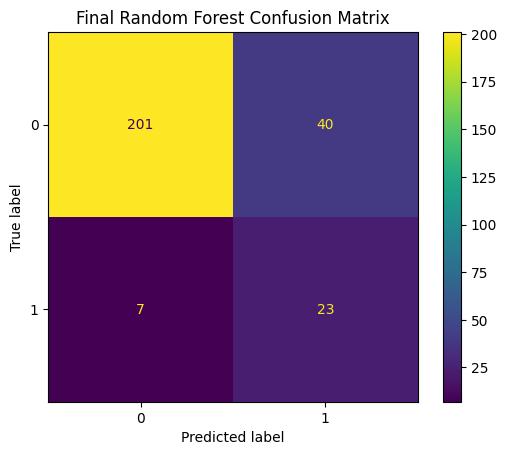

In [115]:
# Final Random Forest confusion matrix

ConfusionMatrixDisplay.from_predictions(
    y_test,
    final_rf_predictions
)

plt.title(
    "Final Random Forest Confusion Matrix"
)

plt.show()

In [116]:
# Get feature names after preprocessing

preprocessor_fitted = final_rf.named_steps[
    "preprocessor"
]

encoded_features = preprocessor_fitted.named_transformers_[
    "cat"
].named_steps[
    "encoder"
].get_feature_names_out(
    categorical_features
)

all_feature_names = (
    numerical_features
    + list(encoded_features)
)

all_feature_names[:10]

['LoanBalance',
 'Age',
 'Income',
 'Product_Business Loan',
 'Product_Gold Loan',
 'Product_Housing Loan',
 'Product_Leasing',
 'Product_Personal Loan',
 'CustomerCategory_Business Medium',
 'CustomerCategory_Business Small']

In [117]:
# Get Random Forest feature importances

rf_classifier = final_rf.named_steps[
    "model"
]

feature_importance = pd.DataFrame({
    "Feature": all_feature_names,
    "Importance": rf_classifier.feature_importances_
}).sort_values(
    "Importance",
    ascending=False
)

feature_importance.head(15)

,Feature,Importance
23,CRIB Category_E,0.331785
19,CRIB Category_A,0.132001
20,CRIB Category_B,0.121398
21,CRIB Category_C,0.076847
0,LoanBalance,0.073138
2,Income,0.072759
1,Age,0.045221
22,CRIB Category_D,0.036622
3,Product_Business Loan,0.018939
9,CustomerCategory_Business Small,0.012771


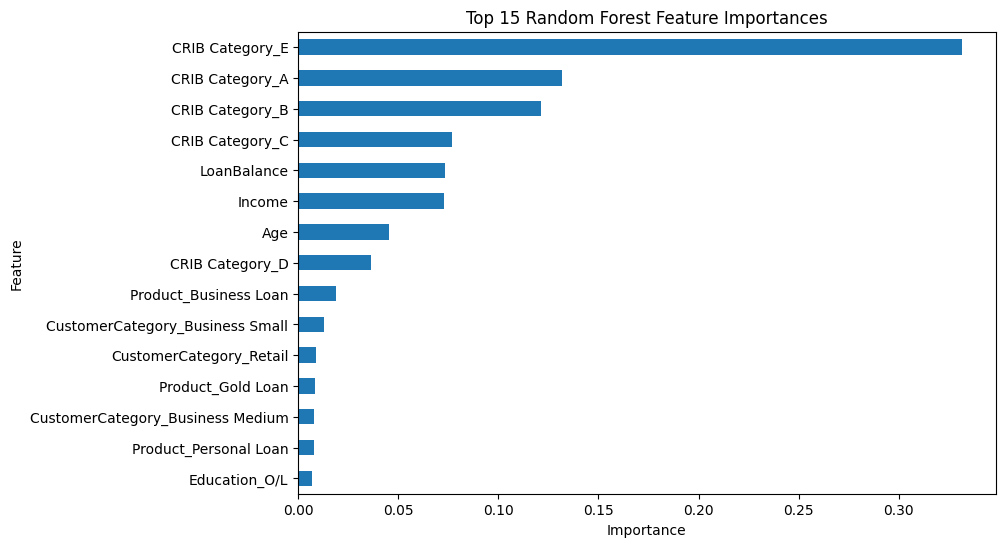

In [118]:
# Plot top 15 features

top_features = feature_importance.head(15)

top_features.sort_values(
    "Importance"
).plot(
    x="Feature",
    y="Importance",
    kind="barh",
    legend=False,
    figsize=(9, 6)
)

plt.title(
    "Top 15 Random Forest Feature Importances"
)

plt.xlabel(
    "Importance"
)

plt.show()

In [121]:
# Save final Random Forest model

joblib.dump(
    final_rf,
    "npl_risk_model.pkl"
)

joblib.dump(
    list(X.columns),
    "model_features.pkl"
)

final_comparison.to_csv(
    "model_comparison.csv",
    index=False
)

feature_importance.to_csv(
    "feature_importance.csv",
    index=False
)

print(
    "Model and dashboard files saved successfully."
)

Model and dashboard files saved successfully.
